# 🎼 Market Symphony — Exploration et choix du modèle

*Sheila Songkana — PGE 2, Aivancity · Semaines 1 et 2 du projet*

> Projet éducatif — pas de conseil en investissement.

## 0. Pourquoi ce projet ?

### Le problème
Les marchés financiers sont presque toujours montrés de la même façon : **une courbe de prix et des tableaux de chiffres**. Pour un public non initié, cette représentation est muette : difficile de *ressentir* la différence entre une année tranquille comme 2017 et l'effondrement de l'automne 2008, ou de comprendre ce que signifie concrètement « la volatilité explose ».

### L'idée
**Market Symphony** propose une autre lecture : **écouter et voir le marché**.
- Chaque **séance de bourse** devient une **note de musique** et une **forme animée**.
- Quand le marché change d'humeur, **toute l'ambiance change** : gamme musicale, instrument, tempo, couleurs, formes.

Un krach doit *sonner* comme un krach — dissonant, rapide, rouge — et un marché serein doit *sonner* serein. L'objectif est qu'un non-spécialiste **entende** la différence en moins de 30 secondes.

### Le rôle de l'intelligence artificielle
Pour que l'ambiance change au bon moment, il faut savoir, **jour par jour**, dans quel « état d'esprit » se trouve le marché. C'est ce qu'on appelle un **régime de marché** : une phase durable aux caractéristiques stables (tendance, niveau d'agitation). On en distingue quatre :

| Régime | Ce qui se passe | Ce qu'on entend | Ce qu'on voit |
|---|---|---|---|
| 🟢 **Haussier** | Les prix montent avec confiance, peu de secousses | Gamme pentatonique, rythme vif | Verts et dorés, spirales ascendantes |
| 🔵 **Calme** | Pas de tendance nette, agitation modérée | Gamme majeure, piano doux | Bleus, formes rondes et lentes |
| 🟠 **Nerveux** | L'incertitude monte, le marché hésite et chute par à-coups | Gamme mineure, staccato | Orangés, formes anguleuses |
| 🔴 **Panique** | Krach : forte baisse et agitation extrême | Dissonances, percussions graves | Rouges, éclats et dispersion |

Personne ne publie la liste officielle de ces régimes : **il n'existe pas de « bonne réponse » à apprendre**. Il faut donc que l'algorithme les **découvre seul** dans les données. C'est un problème d'**apprentissage non supervisé**, et c'est l'objet de ce notebook.

### Ce que le projet ne fait pas
Market Symphony **décrit** le passé, il ne **prédit** pas les prix. Ce choix est volontaire : selon l'hypothèse de la *marche aléatoire* (B. Malkiel, *A Random Walk Down Wall Street*), les variations futures sont essentiellement imprévisibles. En revanche, l'*humeur* du marché — calme ou agité — est persistante et donc observable : c'est elle que l'on met en musique.

## Vue d'ensemble du pipeline

```
 Prix journaliers        Indicateurs           Modèle IA             Partition            Œuvre
 (Yahoo Finance)   ──►   (features)      ──►   (HMM)           ──►   audiovisuelle  ──►   (navigateur)
 S&P 500 2000→2026       rendement,            un régime             note, tempo,         Tone.js (son)
 cache Parquet           volatilité,           par jour              couleur, forme       p5.js (image)
                         drawdown…
 └──────────── ce notebook (entraînement hors ligne) ────────────┘   └── API FastAPI ──┘   └ React ┘
```

### Ce que fait ce notebook
1. **Charger** 26 ans d'historique du S&P 500, l'indice des 500 plus grandes entreprises américaines, pour couvrir plusieurs crises (bulle Internet, 2008, Covid).
2. **Construire les indicateurs** (*features*) qui décrivent l'humeur du marché chaque jour.
3. **Choisir le nombre de régimes** avec un critère statistique (BIC).
4. **Comparer deux modèles** : K-Means (simple, référence) et le **modèle de Markov caché** (HMM, modèle principal).
5. **Vérifier** que les résultats ont un sens historique.

### Critères de réussite (cahier des charges §4.3 et §10)
- ✅ Les crises de **2008** et de **mars 2020** doivent être classées en *panique*.
- ✅ Le nombre de régimes doit être **justifié** (BIC, silhouette).
- ✅ Les régimes doivent être **stables** : un régime dure plusieurs jours, sinon la musique changerait d'ambiance à chaque note.

In [1]:
import sys
sys.path.insert(0, '../backend')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

from app.core.config import get_config
from app.core.constant import REGIME_PROFILES, Regime, MODELS_DIR, HMM_MODEL_FILENAME, KMEANS_MODEL_FILENAME
from app.data.fetcher import load_prices
from app.features.engineering import compute_features, feature_columns
from app.models.regimes import RegimeModel, mean_regime_duration

cfg = get_config()
np.random.seed(cfg['project']['random_seed'])
COLORS = {r.value: p['color'] for r, p in REGIME_PROFILES.items()}
plt.rcParams.update({'figure.figsize': (13, 4), 'axes.grid': True, 'grid.alpha': .3})

## 1. Données

Pour chaque jour de bourse on dispose de 5 valeurs (**OHLCV**) : prix d'ouverture (*Open*), plus haut (*High*), plus bas (*Low*), clôture (*Close*) et nombre de titres échangés (*Volume*). Les prix sont **ajustés** des dividendes et divisions d'actions, pour qu'une variation reflète un vrai mouvement de marché.

Les données sont mises en cache au format **Parquet** : la démo ne dépend pas de la disponibilité de Yahoo Finance.

In [2]:
tr = cfg['data']['training']
prices = load_prices(tr['ticker'], tr['start'], tr['end'])
print(f"{len(prices)} séances, {prices.index[0].date()} → {prices.index[-1].date()}")
prices.tail()

6757 séances, 2000-01-03 → 2026-11-12


Price,open,high,low,close,volume
date,,,,,
2026-11-06,7377.649902,7444.200195,7369.549805,7376.859863,5701900000
2026-11-09,7422.240234,7577.390137,7422.240234,7549.939941,5819360000
2026-11-10,7513.089844,7543.919922,7470.430176,7520.930176,5056350000
2026-11-11,7586.649902,7647.200195,7571.879883,7619.379883,4493200000
2026-11-12,7550.839844,7652.759766,7550.839844,7592.399902,4693040000


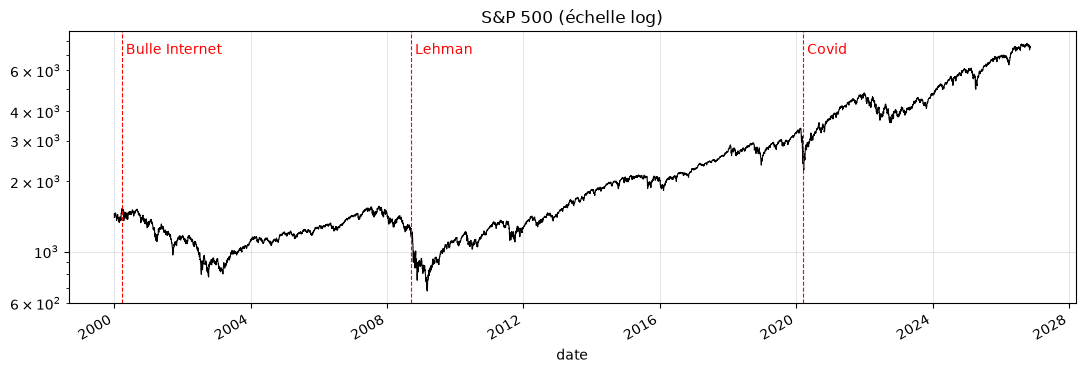

In [3]:
ax = prices['close'].plot(logy=True, color='k', lw=.8, title='S&P 500 (échelle log)')
for d, label in [('2000-03-24', 'Bulle Internet'), ('2008-09-15', 'Lehman'), ('2020-03-16', 'Covid')]:
    ax.axvline(pd.Timestamp(d), color='r', ls='--', lw=.8); ax.text(pd.Timestamp(d), ax.get_ylim()[1]*.8, f' {label}', color='r')
plt.show()

## 2. Features : décrire l'humeur du marché en chiffres (§4.1)

Le prix seul ne dit pas si le marché est serein ou paniqué. On calcule donc, pour chaque jour, des indicateurs qui répondent chacun à une question simple :

| Feature | Question | Calcul | Rôle dans l'œuvre |
|---|---|---|---|
| `log_return` | Le marché a-t-il monté ou baissé aujourd'hui ? | ln(Pₜ / Pₜ₋₁) | **Hauteur** de la note (hausse = aigu) |
| `volatility` | Le marché est-il agité ? | écart-type des rendements sur 20 j × √252 | **Tempo**, réverbération, agitation des particules |
| `momentum_20`, `momentum_60` | Quelle est la tendance du dernier mois / trimestre ? | somme des rendements sur 20 / 60 j | aide le modèle à reconnaître le régime |
| `drawdown` | À quelle distance sommes-nous du dernier sommet ? | Pₜ / max sur 252 j − 1 | gravité d'une chute |
| `relative_volume` | Les investisseurs se bousculent-ils ? | volume / moyenne sur 20 j | **intensité** de la note, luminosité |

*La multiplication par √252 (nombre de séances par an) exprime la volatilité en base annuelle : 0,15 = « ±15 % par an ».*

In [4]:
features = compute_features(prices)
cols = feature_columns()
features[cols].describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
log_return,6697.0,0.0002,0.0121,-0.1277,-0.0047,0.0006,0.0059,0.1096
volatility,6697.0,0.1619,0.1053,0.0328,0.0977,0.1355,0.1937,0.9790
momentum_20,6697.0,0.0050,0.0469,-0.3703,-0.0164,0.0118,0.0318,0.2110
momentum_60,6697.0,0.0151,0.0766,-0.5326,-0.0185,0.0292,0.0620,0.3304
drawdown,6697.0,-0.0665,0.0911,-0.5258,-0.0905,-0.0269,-0.0059,0.0000
relative_volume,6697.0,1.0047,0.1761,0.2221,0.9055,0.9917,1.0877,2.0936


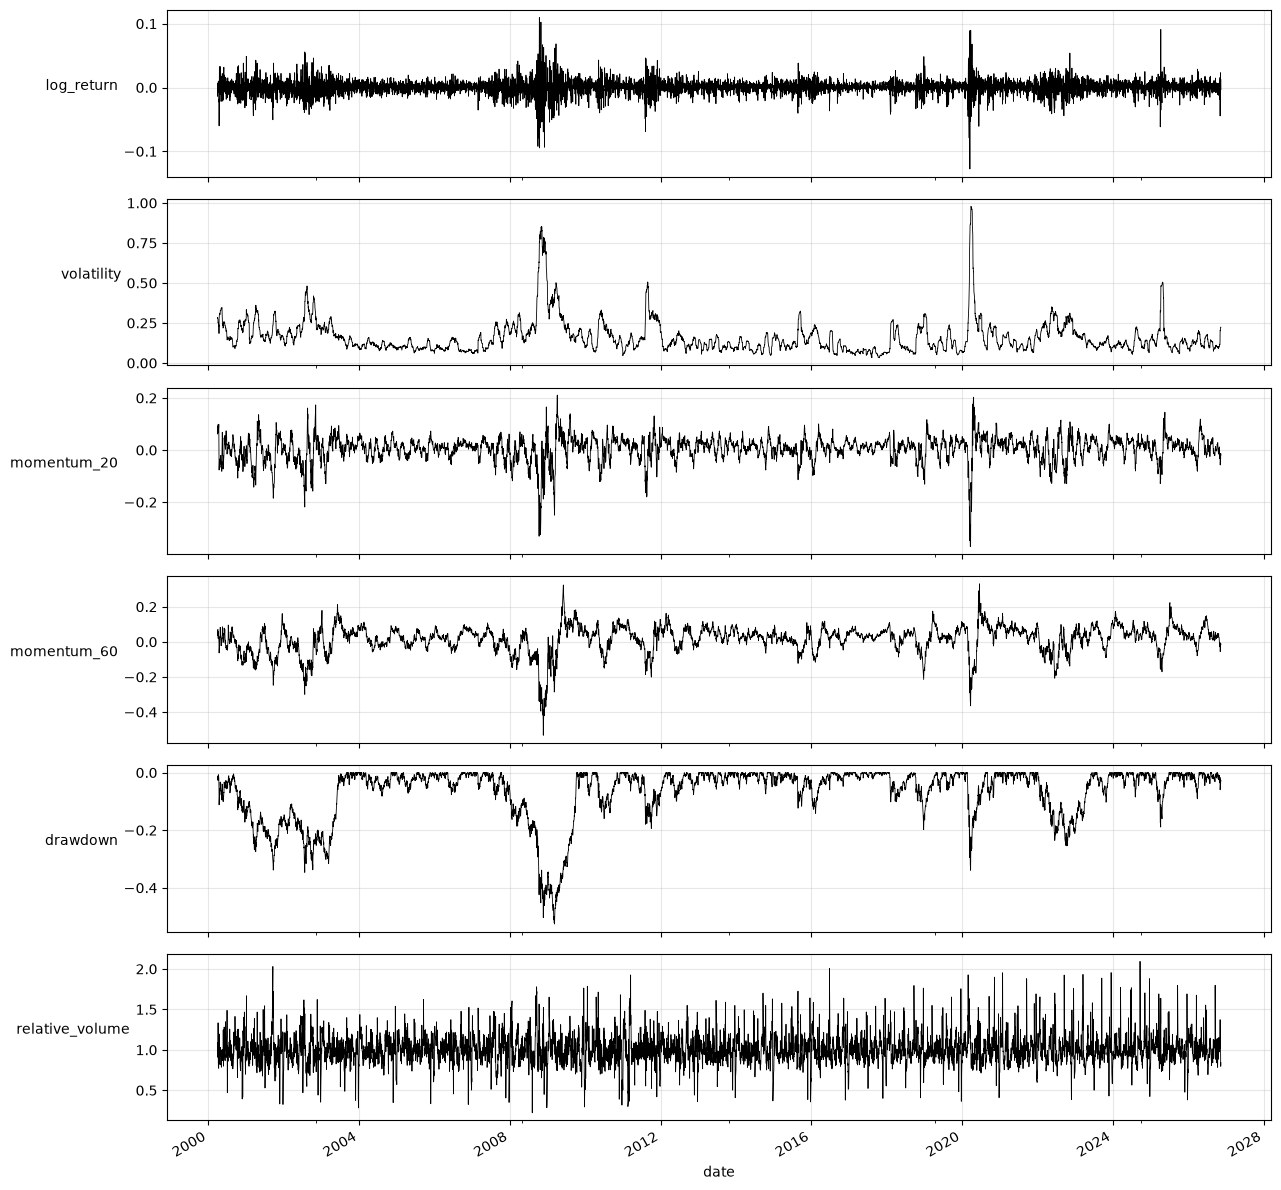

In [5]:
fig, axes = plt.subplots(len(cols), 1, figsize=(13, 2*len(cols)), sharex=True)
for ax, c in zip(axes, cols):
    features[c].plot(ax=ax, lw=.6, color='k'); ax.set_ylabel(c, rotation=0, ha='right')
plt.tight_layout(); plt.show()

In [6]:
features[cols].corr().round(2)

Price,log_return,volatility,momentum_20,momentum_60,drawdown,relative_volume
Price,,,,,,
log_return,1.00,-0.00,0.22,0.12,0.09,-0.08
volatility,-0.00,1.00,-0.40,-0.66,-0.73,-0.05
momentum_20,0.22,-0.40,1.00,0.54,0.38,-0.15
momentum_60,0.12,-0.66,0.54,1.00,0.60,-0.05
drawdown,0.09,-0.73,0.38,0.60,1.00,-0.03
relative_volume,-0.08,-0.05,-0.15,-0.05,-0.03,1.00


**Lecture** : la volatilité et le drawdown sont fortement corrélés (négativement) en période de crise ; le volume relatif est le signal le plus bruité. Les rendements présentent des queues épaisses (kurtosis élevé), d'où l'intérêt d'un modèle à états plutôt qu'une simple loi normale.

In [7]:
print('Kurtosis des rendements :', round(features['log_return'].kurt(), 1), '(loi normale = 0)')

Kurtosis des rendements : 10.9 (loi normale = 0)


## 3. Combien de régimes ? (BIC)

Le **modèle de Markov caché (HMM)** suppose que le marché se trouve chaque jour dans un **état caché** (le régime), qu'on ne voit pas directement, mais qui « produit » les indicateurs observés. Chaque régime a sa propre façon de générer les rendements et la volatilité, et le modèle apprend aussi **la probabilité de passer d'un régime à l'autre** d'un jour au suivant.

Plus on autorise d'états, mieux le modèle colle aux données, mais il risque de « sur-apprendre ». Le **BIC** (*Bayesian Information Criterion*) arbitre entre qualité d'ajustement et complexité : **plus il est bas, meilleur est le compromis**.

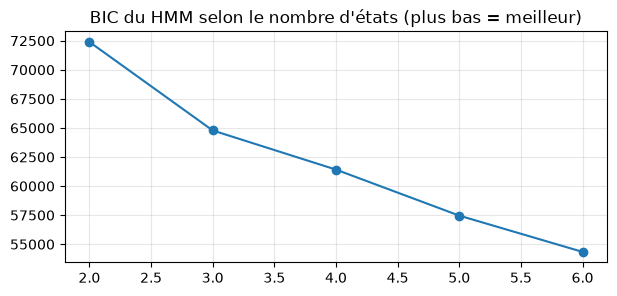

2    72399.0
3    64785.0
4    61417.0
5    57460.0
6    54342.0
Name: BIC, dtype: float64

In [8]:
X = None
bic = {}
for n in cfg['models']['selection']['candidate_states']:
    m = RegimeModel.fit(features, cols, kind='hmm', n_states=n)
    X = m.scaler.transform(features[cols].to_numpy())
    bic[n] = m.model.bic(X)
pd.Series(bic, name='BIC').plot(marker='o', title='BIC du HMM selon le nombre d\'états (plus bas = meilleur)', figsize=(7, 3))
plt.show()
pd.Series(bic, name='BIC').round(0)

**Décision** : le BIC continue de baisser au-delà de 4 états — classique sur un grand échantillon (~6 700 points), où le terme de pénalité pèse peu. Le « coude » se situe vers 3–4 états. On retient **4 états**, imposés par l'interprétabilité et la conception musicale (4 ambiances), et parce que le gain marginal au-delà diminue. Ce compromis est documenté dans EVOLUTION.md.

## 4. K-Means vs HMM : pourquoi la mémoire compte

- **K-Means** regroupe les jours qui se ressemblent, **chaque jour indépendamment des autres**. Simple et rapide : c'est notre modèle de référence.
- **Le HMM** tient compte de l'**ordre des jours** : s'il était en panique hier, il est très probable qu'il le soit encore aujourd'hui. Cette *persistance temporelle* évite les changements de régime parasites.

Pour la musique, la différence est essentielle : un modèle qui change de régime tous les deux jours donnerait une œuvre décousue, alors qu'un régime qui dure quelques semaines installe une **ambiance**.

**Nommage automatique.** Les modèles renvoient des numéros d'état (0, 1, 2, 3) sans signification. On leur donne un nom d'après leurs caractéristiques moyennes : volatilité la plus forte → *panique* ; meilleur rapport rendement/volatilité → *haussier* ; la plus agitée des deux restantes → *nerveux* ; la dernière → *calme*.

In [9]:
km = RegimeModel.load(MODELS_DIR / KMEANS_MODEL_FILENAME)
hmm = RegimeModel.load(MODELS_DIR / HMM_MODEL_FILENAME)
reg = {'kmeans': km.predict(features), 'hmm': hmm.predict(features)}

def summary(r):
    return (features.assign(regime=r).groupby('regime')
            .agg(jours=('close', 'size'),
                 rendement_annuel=('log_return', lambda x: x.mean()*252),
                 volatilite=('volatility', 'mean'),
                 drawdown=('drawdown', 'mean'))
            .reindex([r.value for r in Regime]).round(3))

for k, r in reg.items():
    print(f'=== {k} — durée moyenne d\'un régime : {mean_regime_duration(r):.1f} jours'); display(summary(r))
print('Silhouette K-Means :', round(silhouette_score(km.scaler.transform(features[cols].to_numpy()), km.predict_states(features)), 3))

=== kmeans — durée moyenne d'un régime : 5.7 jours


,jours,rendement_annuel,volatilite,drawdown
regime,,,,
calm,4444,0.405,0.118,-0.021
bull,1058,1.807,0.264,-0.176
nervous,1048,-2.833,0.184,-0.107
panic,147,-2.283,0.595,-0.355


=== hmm — durée moyenne d'un régime : 31.4 jours


,jours,rendement_annuel,volatilite,drawdown
regime,,,,
calm,2346,-0.004,0.141,-0.033
bull,2290,0.252,0.094,-0.005
nervous,1742,0.016,0.224,-0.166
panic,319,-0.588,0.468,-0.215


Silhouette K-Means : 0.324


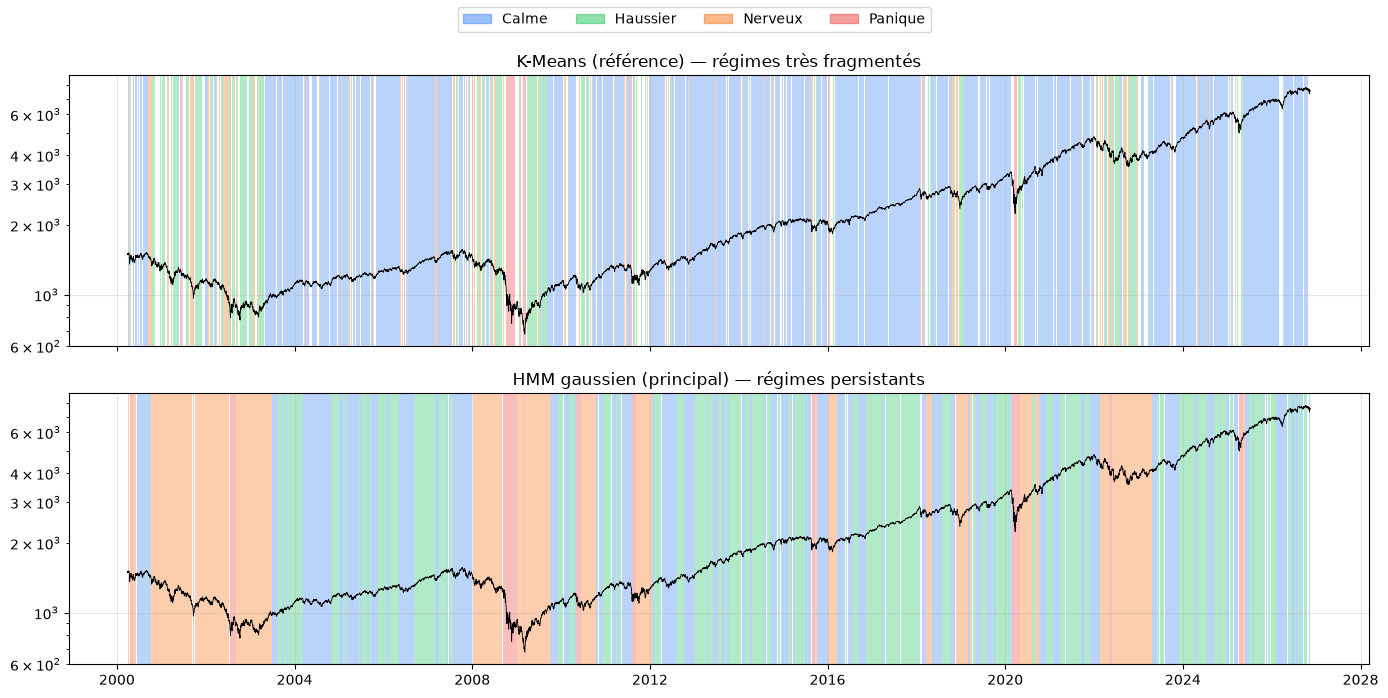

In [10]:
def plot_regimes(r, title, ax):
    ax.plot(features.index, features['close'], color='k', lw=.6)
    ax.set_yscale('log')
    for regime, color in COLORS.items():
        mask = (r == regime).to_numpy()
        ax.fill_between(features.index, 0, 1, where=mask, color=color, alpha=.35, transform=ax.get_xaxis_transform(), lw=0)
    ax.set_title(title)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
plot_regimes(reg['kmeans'], 'K-Means (référence) — régimes très fragmentés', axes[0])
plot_regimes(reg['hmm'], 'HMM gaussien (principal) — régimes persistants', axes[1])
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=.5) for c in COLORS.values()]
fig.legend(handles, [REGIME_PROFILES[Regime(k)]['label_fr'] for k in COLORS], loc='upper center', ncol=4)
plt.tight_layout(rect=(0, 0, 1, .95))
fig.savefig('../docs/regimes_sp500.png', dpi=120, bbox_inches='tight')
plt.show()

**Lecture** : K-Means regroupe les jours surtout selon le *signe du rendement du jour* — il change de régime toutes les ~6 séances et mélange hausses de rebond et euphorie. Le HMM, grâce à sa matrice de transition, produit des régimes qui durent ~1 mois et correspondent aux phases que l'on lit sur la courbe.

## 5. Cohérence historique (§4.3)

Faute de « bonne réponse » officielle, on vérifie que le modèle retrouve les grands épisodes connus de l'histoire financière (voir le tableau des événements du cahier des charges, §12.3).

In [11]:
periods = {
    'Bulle Internet (2001-2002)': ('2001-01-01', '2002-10-31'),
    'Lehman (sept.–nov. 2008)': ('2008-09-15', '2008-11-30'),
    'Flash crash (mai 2010)': ('2010-05-01', '2010-06-30'),
    'Marché haussier 2017': ('2017-01-01', '2017-12-31'),
    'Covid (mars 2020)': ('2020-03-01', '2020-03-31'),
    'Marché baissier 2022': ('2022-01-01', '2022-10-31'),
}
rows = {name: reg['hmm'].loc[a:b].value_counts(normalize=True) for name, (a, b) in periods.items()}
(pd.DataFrame(rows).T.reindex(columns=[r.value for r in Regime]).fillna(0) * 100).round(0).astype(int).style.background_gradient(cmap='Reds', axis=None).format('{} %')

regime,calm,bull,nervous,panic
Bulle Internet (2001-2002),0 %,0 %,89 %,11 %
Lehman (sept.–nov. 2008),0 %,0 %,0 %,100 %
Flash crash (mai 2010),7 %,0 %,31 %,62 %
Marché haussier 2017,7 %,93 %,0 %,0 %
Covid (mars 2020),0 %,0 %,0 %,100 %
Marché baissier 2022,15 %,0 %,76 %,9 %


✅ **Critère de réussite atteint** : sept.–nov. 2008 et mars 2020 sont classés à 100 % en *panique*. 2017 est reconnu comme haussier et 2022 comme nerveux.

## 6. Matrice de transition (bonus)

In [12]:
tm = hmm.transition_matrix()
tm.index = tm.columns = [REGIME_PROFILES[Regime(r)]['label_fr'] for r in tm.index]
(tm * 100).round(1).style.background_gradient(cmap='Blues').format('{:.1f} %')

,Calme,Haussier,Nerveux,Panique
Calme,95.7 %,3.6 %,0.4 %,0.2 %
Haussier,3.8 %,96.2 %,0.0 %,0.0 %
Nerveux,0.9 %,0.0 %,98.6 %,0.5 %
Panique,0.0 %,0.0 %,4.3 %,95.7 %


In [13]:
print('Durée moyenne attendue de chaque régime (1 / (1 - p_ii)) :')
(1 / (1 - pd.Series(np.diag(tm), index=tm.index))).round(0)

Durée moyenne attendue de chaque régime (1 / (1 - p_ii)) :


Calme       23.0
Haussier    26.0
Nerveux     74.0
Panique     23.0
dtype: float64

**Lecture** : les probabilités de rester dans le même régime sont > 95 % (persistance). Les transitions dessinent une **échelle** : *haussier ↔ calme ↔ nerveux ↔ panique*. Un marché haussier ne bascule jamais directement en panique (0 %) ; après un krach, la seule sortie est la phase *nerveuse* (4,3 %/jour), avant un retour progressif au calme. C'est cette trajectoire qu'on entendra dans la musique.

## 7. Conclusion et suite du projet

| Critère | Résultat |
|---|---|
| 2008 et mars 2020 en *panique* | ✅ 100 % avec le HMM |
| Nombre de régimes justifié | ✅ 4 états : coude du BIC, interprétabilité, 4 ambiances musicales |
| Stabilité | ✅ un régime dure en moyenne ~1 mois (HMM) contre ~6 jours (K-Means) |

**Le HMM à 4 états est retenu** et sauvegardé (`models/hmm_regimes.joblib`). L'API FastAPI le charge pour attribuer un régime à chaque jour de n'importe quelle période, puis traduit chaque séance en paramètres sonores et visuels. Le frontend (Tone.js + p5.js) n'a plus qu'à jouer cette partition.

## 8. Limites
- Modèle entraîné sur le S&P 500 : appliqué au Bitcoin (volatilité structurellement plus forte), il surreprésente *nerveux* / *panique*.
- Le HMM est ajusté sur toute la série (lissage *a posteriori*) : il décrit le passé, il ne prédit rien.
- Les noms des régimes résultent de règles (volatilité, ratio rendement/volatilité) et non d'une vérité terrain.